# CS 273 — Project 2.3: Restaurant Review Sentiment Classification

In this notebook, I predict whether a restaurant review is **negative (0)** or **positive (1)**. I will train and compare three machine-learning models.

This project uses the same restaurant review dataset as Part 2.1, but the target instead is sentiment, not fake/real. The ten features from Part 2.1 or the cyberattack data from Part 2.2 are therefore not needed.

**To run:** Place `restaurant_reviews-v2-1.xlsx` in the same folder as this notebook. Run all cells from top to bottom.

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42

## 2. Load and inspect the dataset

The original file includes the review text, fake/real labels, sentiment labels, and older linguistic features. Only the review text is used as the input, and only the sentiment column is used as the label.

We remove missing/blank reviews and exact duplicate review texts. Removing duplicates before splitting helps prevent identical reviews from appearing in both the training and test sets.

In [2]:
raw = pd.read_excel('restaurant_reviews-v2-1.xlsx')

# Keep only the columns needed
df = raw[['Review', 'positive=1/negative=0']].copy()
df.columns = ['review', 'sentiment']

print('Original number of reviews:', len(df))
print('Missing values:')
print(df.isna().sum())
df.head()

Original number of reviews: 260
Missing values:
review       0
sentiment    0
dtype: int64


,review,sentiment
0,Great food and great atmosphere! The chicken t...,1
1,I had heard good things about Tikka Shak so I ...,0
2,I was driving by tikka shack one day and decid...,0
3,Tikka Shack had the most modern and up-to-date...,1
4,Today is the third time I've come to India Pal...,1


In [3]:
df = df.dropna(subset=['review', 'sentiment']).copy()
df['review'] = df['review'].astype(str).str.strip()
df = df[df['review'] != ''].copy()

# Do not allow duplicate review text to leak into both sets
duplicates = df.duplicated(subset=['review']).sum()
df = df.drop_duplicates(subset=['review']).reset_index(drop=True)
df['sentiment'] = df['sentiment'].astype(int)

assert set(df['sentiment'].unique()) == {0, 1}
print('Exact duplicate reviews removed:', duplicates)
print('Reviews remaining:', len(df))
print('Sentiment distribution (0 = negative, 1 = positive):')
print(df['sentiment'].value_counts().sort_index())

Exact duplicate reviews removed: 4
Reviews remaining: 256
Sentiment distribution (0 = negative, 1 = positive):
0    124
1    132
Name: sentiment, dtype: int64


## 3. Shuffle and split the data (80% train, 20% test)

I use a stratified split so positive and negative reviews stay in approximately the same proportions in both sets. `shuffle=True` randomizes the rows, and the fixed seed makes the result reproducible.

The test set will be kept separate until evaluation. Each model learns only from the training set.

In [4]:
X = df['review']     # Input: review text only
Y = df['sentiment']  # Target: sentiment only

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.20,
    stratify=Y,
    shuffle=True,
    random_state=SEED
)

print('Training reviews:', len(X_train))
print('Test reviews:', len(X_test))

split_table = pd.DataFrame({
    'Train': y_train.value_counts().sort_index(),
    'Test': y_test.value_counts().sort_index()
})
split_table.index = ['Negative (0)', 'Positive (1)']
print()
print('Sentiment labels in each split:')
print(split_table)

assert abs(len(X_train) / len(df) - 0.80) < 0.01
assert len(set(X_train.index) & set(X_test.index)) == 0
assert len(set(X_train) & set(X_test)) == 0
assert abs(y_train.mean() - y_test.mean()) < 0.05

Training reviews: 204
Test reviews: 52

Sentiment labels in each split:
              Train  Test
Negative (0)     99    25
Positive (1)    105    27


## 4. Preprocessing and model choices

I use TF-IDF to turn review text into numerical features since it gives more weight to informative words and phrases. I include single words and two-word phrases (unigrams and bigrams), which can understand phrases such as "not good".

I keep the review wording mostly unchanged. The TF-IDF vectorizer handles lowercasing and tokenization, so I do not use stemming or remove stopwords because negation words such as "not" are important for sentiment.

I train three different classifiers:

1. **Logistic Regression:** a linear model for predicting the probability of positive sentiment.
2. **Multinomial Naive Bayes:** a simple probabilistic model well suited to nonnegative text features such as TF-IDF.
3. **Linear SVM:** a margin-based linear classifier that often works well with sparse text features.

The `make_pipeline` function ensures that TF-IDF is fitted only on training data, so test text does not influence the vocabulary or word weights.

In [5]:
# Build a text-classification pipeline for any of the three classifiers above
def make_text_model(classifier):
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2),
        classifier
    )

models = {
    'Logistic Regression': make_text_model(LogisticRegression(max_iter=2000, random_state=SEED)),
    'Multinomial Naive Bayes': make_text_model(MultinomialNB()),
    'Linear SVM': make_text_model(LinearSVC(random_state=SEED))
}

print('Models to train:', list(models))

Models to train: ['Logistic Regression', 'Multinomial Naive Bayes', 'Linear SVM']


## 5. Train the three models

Each model fits its own TF-IDF vectorizer and classifier using the training set only. The model settings are fixed in advance so the test data is not used for training or tuning.

In [6]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print('Trained:', name)

Trained: Logistic Regression
Trained: Multinomial Naive Bayes
Trained: Linear SVM


## 6. Evaluate on both train and test data

I compare accuracy and F1-score using positive sentiment (1) as the positive class.

- **Accuracy** is the proportion of predictions that are correct.
- **Precision** measures how many predicted positives are truly positive.
- **Recall** measures how many actual positives are detected.
- **F1-score** balances precision and recall.

Let TP, TN, FP, and FN be the counts of true positives, true negatives, false positives, and false negatives:

$$\mathrm{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

$$\mathrm{Precision} = \frac{TP}{TP + FP}, \quad \mathrm{Recall} = \frac{TP}{TP + FN}$$

$$F_1 = \frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision} + \mathrm{Recall}} = \frac{2TP}{2TP + FP + FN}$$

Comparing train and test scores also helps spot overfitting, which is when a model performs much better on reviews it trained on than on unseen reviews.

In [7]:
def evaluate(y_true, predictions):
    return accuracy_score(y_true, predictions), f1_score(y_true, predictions, pos_label=1)

results = []
for name, model in models.items():
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)
    train_acc, train_f1 = evaluate(y_train, train_predictions)
    test_acc, test_f1 = evaluate(y_test, test_predictions)

    results.append({
        'Model': name,
        'Train Accuracy': train_acc,
        'Train F1': train_f1,
        'Test Accuracy': test_acc,
        'Test F1': test_f1
    })

# Exactly one row per model.
comparison = pd.DataFrame(results)
comparison.round(3)

,Model,Train Accuracy,Train F1,Test Accuracy,Test F1
0,Logistic Regression,1.000,1.000,0.865,0.868
1,Multinomial Naive Bayes,0.995,0.995,0.846,0.862
2,Linear SVM,1.000,1.000,0.846,0.840


In [8]:
# Save the comparison table
comparison.to_csv('sentiment_model_comparison.csv', index=False)
print('Saved sentiment_model_comparison.csv')

Saved sentiment_model_comparison.csv


## 7. Compare the models and check for overfitting

The bar chart compares the training and test F1-scores. A large train-to-test gap can suggest overfitting, while a small gap suggests the model behaves more consistently across these two sets.

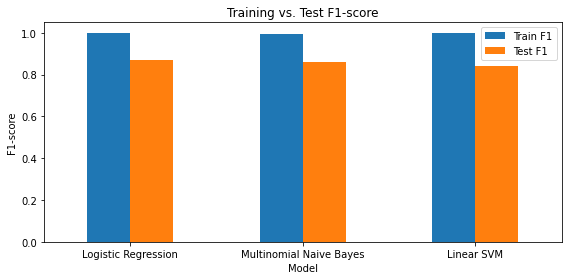

In [9]:
comparison.set_index('Model')[['Train F1', 'Test F1']].plot(kind='bar', figsize=(8, 4))
plt.title('Training vs. Test F1-score')
plt.ylabel('F1-score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('sentiment_f1_comparison.png', dpi=160)
plt.show()

In [10]:
# Print observations
comparison['F1 Gap'] = comparison['Train F1'] - comparison['Test F1']

best_row = comparison.loc[comparison['Test F1'].idxmax()]
best_name = best_row['Model']

print('Highest test F1:', best_name, f"({best_row['Test F1']:.3f})")
print()
print('Train minus test F1 (larger positive gap may mean more overfitting):')
print(comparison[['Model', 'F1 Gap']].round(3).to_string(index=False))

Highest test F1: Logistic Regression (0.868)

Train minus test F1 (larger positive gap may mean more overfitting):
                  Model  F1 Gap
    Logistic Regression   0.132
Multinomial Naive Bayes   0.133
             Linear SVM   0.160


## 8. Examine the test predictions

A confusion matrix shows how the highest-test-F1 model classified the 52 (approximately 20%) held-out reviews. The rows are the actual labels and the columns are the predicted labels. A false positive is a negative review predicted as positive, and a false negative is a positive review predicted as negative.

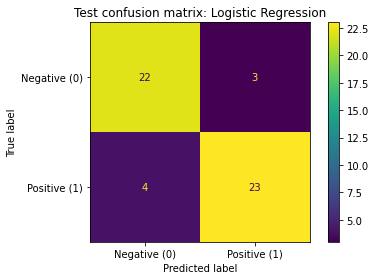

Confusion matrix:
                 Predicted negative  Predicted positive
Actual negative                  22                   3
Actual positive                   4                  23


In [11]:
best_predictions = models[best_name].predict(X_test)
cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])

ConfusionMatrixDisplay(cm, display_labels=['Negative (0)', 'Positive (1)']).plot()
plt.title('Test confusion matrix: ' + best_name)
plt.tight_layout()
plt.savefig('sentiment_confusion_matrix.png', dpi=160)
plt.show()

print('Confusion matrix:')
print(pd.DataFrame(cm,
                   index=['Actual negative', 'Actual positive'],
                   columns=['Predicted negative', 'Predicted positive']))